# Tutorial

This tutorial runs CHART on part of the CellMAPP optical pooled screen of [Coelho, Leote et al. (2026)](https://doi.org/10.64898/2026.10.07.757470): 66 perturbed genes (58 with strong and 8 with weak effects in the full screen) and the screen's controls, about 129,000 cells imaged in four channels.

It runs [preprocessing](preprocessing.md), [effects](effects.md) and [programs](programs.md) as on a full screen, except for two quality checks in preprocessing that require the images; the cells in the download have already passed them. [Archetypes](archetypes.md) is best run on a compute cluster ([Running on a cluster](cluster.md)), so its outputs are included in the download; they were computed from the same cell table that preprocessing produces here. The archetype crops, which require the images, and their [annotation](annotation.md), which requires a language model, are included as well; running the annotation is optional.

The download is about 920 MB. The tutorial takes about 20 minutes on an 8-core laptop and requires 16 GB of memory and 10 GB of free disk space.

Install CHART as described in [Installation](installation.md); `pip install .` is sufficient here. The UMAP embeddings under Preprocessing additionally require `umap-learn`, which is not a CHART dependency: `pip install umap-learn`. Then run the notebook from the top.

## Setup

Paths, number of cores, and imports.

In [1]:
from pathlib import Path

DATA_URL = 'https://zenodo.org/records/23674850/files/chart_tutorial_data.zip'
SHA256 = 'b53c1a23118a18412580a9170083aa0ab8a7352f2405895ebb30b310ff1c5a9f'
WORKDIR = Path('chart_tutorial')   # the download and every output go here
N_JOBS = -1                        # worker processes; -1 uses every core

In [2]:
import hashlib
import json
import logging
import urllib.request
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import seaborn as sns
import umap
import yaml
from matplotlib.lines import Line2D
from scipy.cluster.hierarchy import dendrogram, leaves_list, linkage
from scipy.spatial.distance import pdist, squareform

# Errors only, set before CHART is imported: without images, CHART warns
# from the start that image processing is unavailable, and every stage warns
# of the checks it skips. logging.WARNING shows these; logging.INFO each
# stage's progress as well.
logging.basicConfig(level=logging.ERROR, format='%(asctime)s %(message)s',
                    datefmt='%H:%M:%S', force=True)

from chart.annotation import run_annotation
from chart.dimred.pca import generate_pca_space
from chart.effects import run_effects
from chart.io.config import load_archetypes_config, load_effects_config, load_programs_config
from chart.io.tables import load_table
from chart.normalization.validation import plot_normalization
from chart.preprocessing import run_preprocessing
from chart.programs import run_programs
from chart.programs.workflow import align_to_reference, fit_programs

pd.set_option('display.max_colwidth', None)

## The data

The download contains the per-well input tables and the outputs of `chart archetypes` and `chart annotation`, laid out as a full run would write them: tables under `data_output_dir` (here `data/`), and crops and annotations under `local_output_dir` (here `reports/`).

In [3]:
archive = WORKDIR / 'chart_tutorial_data.zip'
WORKDIR.mkdir(exist_ok=True)
if not archive.exists():
    urllib.request.urlretrieve(DATA_URL, archive)
digest = hashlib.sha256()
with open(archive, 'rb') as f:
    for block in iter(lambda: f.read(1 << 24), b''):
        digest.update(block)
if digest.hexdigest() != SHA256:
    raise ValueError(f'{archive} is incomplete or damaged; delete it and run this cell again')
with zipfile.ZipFile(archive) as files:
    files.extractall(WORKDIR)

data = WORKDIR / 'data'

Under `data/`:

| File | Holds |
|---|---|
| `preprocessing/bywell/<well>-features.parquet` | one row per cell: 1,436 image features, with the cell's label, guide and gene |
| `preprocessing/bywell/<well>-objects.parquet` | segmentation properties of the same cells: areas, centroids and bounding boxes |
| `archetypes/<channel>/robust_archweights-….parquet` | one row per cell: its weights on the channel's archetypes |
| `archetypes/<channel>/k.txt`, `npc.txt` | the number of archetypes and of principal components used for the channel; later stages read them to locate the weights file |

Under `reports/`:

| File | Holds |
|---|---|
| `archetypes/<channel>/crops/` | crops of each archetype's most heavily weighted cells, five per grid, and `top_cells.parquet`, which lists them |
| `archetypes/<channel>/archetype_total_weights.png` | each archetype's total weight across all cells |
| `annotation/<channel>/` | the archetype descriptions written by `chart annotation`, without the HTML dashboards |

[Your data](data.md) describes the well tables.

## The configuration

All stages read a single YAML configuration file. The tutorial sets only a few keys; see [Configuration](configuration.md) for the rest.

In [4]:
config = {
    'data_output_dir': str(data),
    'local_output_dir': str(WORKDIR / 'reports'),
    'n_jobs': N_JOBS,
    'preprocessing_allwells': {'missing_value_threshold': 10000},
    'archetypes': {'channels': ['DAPI1', 'Fibrillarin', 'rpS6', 'TOM20']},
    'effects': {'n_perm': 500},
}
CONFIG = str(WORKDIR / 'tutorial.yaml')


def save_config():
    Path(CONFIG).write_text(yaml.safe_dump(config, sort_keys=False))


save_config()
print(Path(CONFIG).read_text())

data_output_dir: chart_tutorial/data
local_output_dir: chart_tutorial/reports
n_jobs: -1
preprocessing_allwells:
  missing_value_threshold: 10000
archetypes:
  channels:
  - DAPI1
  - Fibrillarin
  - rpS6
  - TOM20
effects:
  n_perm: 500



- `data_output_dir`: where every stage reads its inputs and writes its outputs; here, the unpacked download.
- `local_output_dir`: reports, i.e. the cells and guides removed by each filter, and plots.
- `n_jobs`: the number of worker processes.
- `preprocessing_allwells.missing_value_threshold`: features missing in more cells than this are dropped. The default, 100,000, is about 9% of the full screen's cells; 10,000 is a similar fraction of this subset.
- `archetypes.channels`: the channels to analyse.
- `effects.n_perm`: 500 permutations per test instead of the default 1,000, which reduces the run time by about 40%. For a full analysis, we recommend using at least 1,000.

The archetypes to exclude are selected below from their crops, and the numbers of programs and modules from the data.

## Preprocessing

`chart preprocessing` merges the per-well tables into a single cell table for the screen, in six steps:

1. `qc` flags cells for removal in each well. The `segmentation` check flags cells whose cytoplasm is implausibly large relative to their nucleus; the `pheno` and `pheno_sbs` checks compare each cell's images across imaging rounds. Without images, the latter two are skipped; the cells in the download have already passed them.
2. `filter` removes the flagged cells.
3. `combine` concatenates the wells.
4. `normalize` quantile-normalizes each feature across wells, mapping each well's values rank by rank onto the feature's distribution pooled over all wells.
5. `outliers` removes features with too many missing values or too little variance, then cells with remaining missing values, then outlier cells within each gene.
6. `guides` removes guides discordant with the other guides of their gene (for controls, with the other controls), then guides with too few cells.

See [Preprocessing](preprocessing.md) for details. The run takes about 4 minutes on 8 cores; the command-line equivalent is `chart preprocessing --config chart_tutorial/tutorial.yaml --all-wells`. Plots are saved under `local_output_dir`; quality control also displays two per well, which `%%capture` suppresses here. One of the saved plots is shown below.

In [5]:
%%capture
result = run_preprocessing(CONFIG)

Cells and features remaining after each step:

In [6]:
bywell, allwells = data / 'preprocessing/bywell', data / 'preprocessing/allwells'
identifiers = {'label', 'sgRNA', 'gene_symbol', 'Label', 'Guide', 'Gene', 'Well'}
tables = {
    'filtered': sorted(bywell.glob('*-features.parquet')),
    'segmentation QC': sorted((bywell / 'filtered').glob('*-features.parquet')),
    'normalize': [allwells / 'normalized/allwells-features_cell.parquet'],
    'outliers': [allwells / 'outlier_filtered/allwells-features_cell_outlier_filtered.parquet'],
    'guides': [data / 'guide_filtering/guide_filtered/allwells-features_cell.parquet'],
}


def size(paths):
    files = [pq.ParquetFile(path) for path in paths]
    return {'cells': sum(f.metadata.num_rows for f in files),
            'features': sum(name not in identifiers for name in files[0].schema_arrow.names)}


pd.DataFrame({step: size(paths) for step, paths in tables.items()}).T

,cells,features
filtered,129030,1436
segmentation QC,128977,1436
normalize,128977,1436
outliers,124976,1337
guides,118612,1337


Quality control removes 53 cells with segmentation errors, whose cytoplasm exceeds 15 times the nuclear area. Each subsequent filter logs what it removed under `local_output_dir`; the outlier step's report gives the reason for each dropped feature and the number of cells removed:

In [7]:
reports = WORKDIR / 'reports'
outlier_report = json.loads((reports / 'preprocessing/allwells/filters/outlier_filters.json').read_text())
dropped = pd.Series(outlier_report['dropped_columns'])
print('Features dropped:', dropped.str.contains('missing').map(
    {True: 'too many missing values', False: 'too little variation'}).value_counts().to_dict())
print('Cells removed:', outlier_report['removed_cells'])

Features dropped: {'too little variation': 83, 'too many missing values': 16}
Cells removed: {'outlier': 3443, 'incomplete': 558}


Removed cells either still had missing values (`incomplete`) or were flagged by an isolation forest as outliers among the cells of their gene (`outlier`). The guide step removes the following guides:

In [8]:
guide_filters = pd.read_parquet(reports / 'guide_filtering/filters/guide_filters.parquet')
guide_filters.groupby('reason').Gene.agg(guides='size', genes=lambda genes: ', '.join(sorted(set(genes))))

,guides,genes
reason,,
control,5,NTC
low_cells,12,"COPA, COPB1, COPB2, FAU, FERMT2, HSPA5, PSMA5, PSMB5, RPL18, RPTOR, RSL24D1, SRP68"
perturbation,10,"ATG5, ATP6AP1, LIN37, RPL31, SLC11A2"


`control`: control guides discordant with the other controls; `perturbation`: guides discordant with the other guides of their gene; `low_cells`: guides with fewer than 50 remaining cells. The plot shows each perturbation guide's similarity to the other guides of its gene and, as a reference, to the non-targeting controls; guides whose similarity to their gene falls below the threshold are removed.

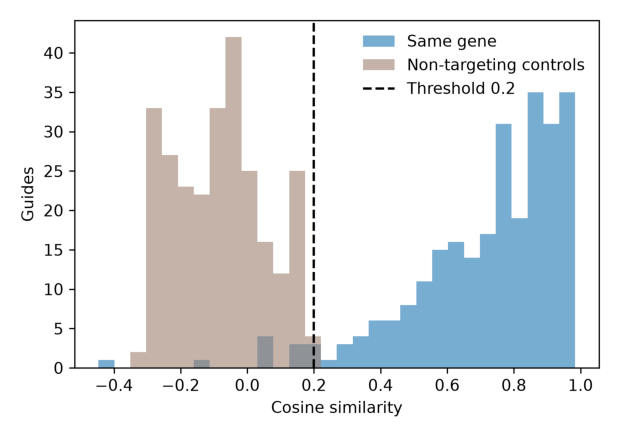

In [9]:
def show_plot(path, width=6):
    image = plt.imread(path)
    fig = plt.figure(figsize=(width, width * image.shape[0] / image.shape[1]))
    ax = fig.add_axes([0, 0, 1, 1])
    ax.imshow(image)
    ax.axis('off')
    plt.show()


show_plot(reports / 'guide_filtering/plots/guide_similarity_comparison.png')

All four guides of LIN37, a weak-effect gene, are discordant, so the gene is removed, leaving 65 perturbed genes.

### Normalization

Wells often present technical differences (e.g. staining, focus). Normalization removes the differences between the wells' feature distributions. The figures below use the same random sample of 20,000 cells.

In [10]:
before = pd.read_parquet(allwells / 'combined/allwells-features.parquet')
cells = before.sample(20000, random_state=0).index
before = before.loc[cells]
after = pd.read_parquet(allwells / 'normalized/allwells-features_cell.parquet').loc[cells]

#### Example features before and after normalization

Per-well densities of three randomly chosen features. The normalize step produces the same figure when run with `validate=True` (`--validate` on the command line).

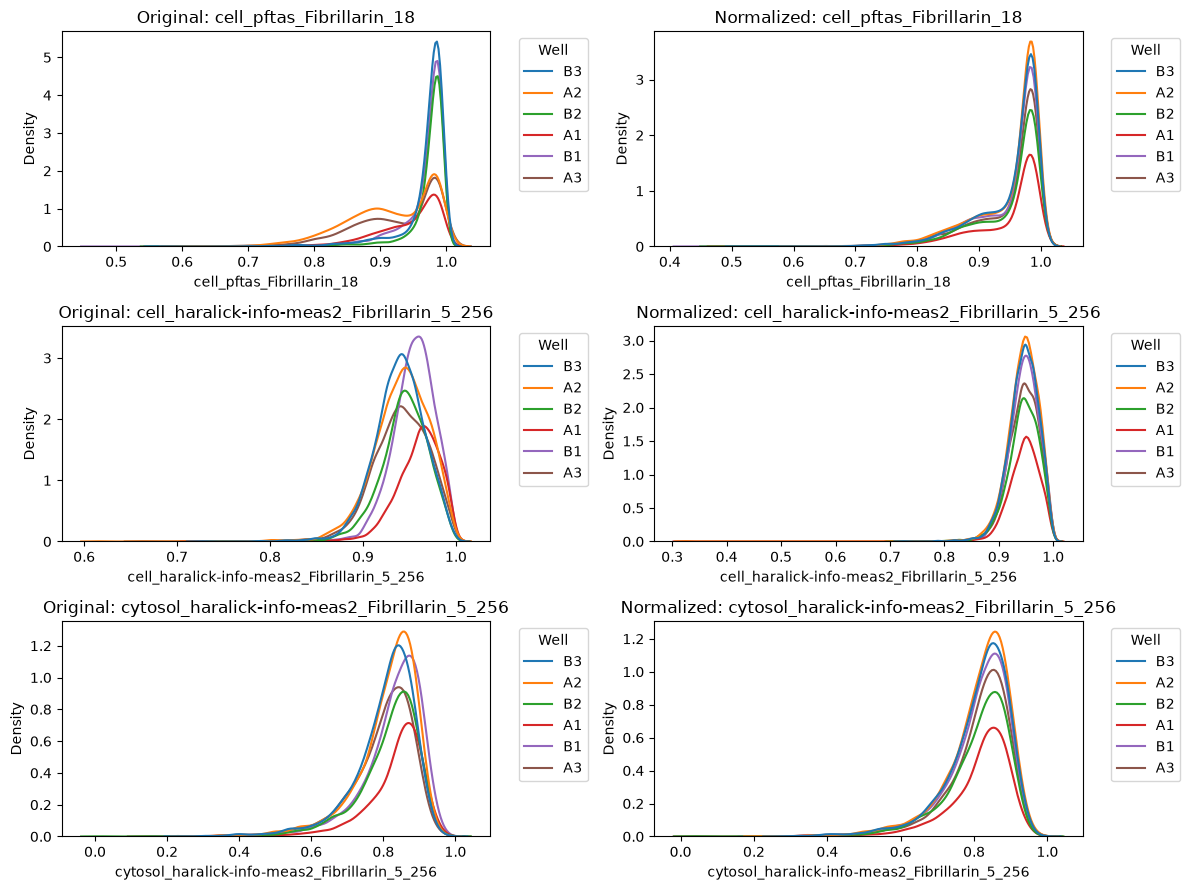

In [11]:
plot_normalization(before, after, sample_features=3, random_state=0)

Before normalization, the distributions differ in shape and location between wells, most for A1, A2 and A3; afterwards they coincide. The remaining differences in height reflect well size, since each density is scaled by its well's share of the cells (A1 has the fewest).

#### Single cell embedding before and after normalization

UMAP embeddings of the cells, coloured by well. They are computed from CHART's PCA of the features without missing values, which standardizes each feature and retains the components explaining 90% of the variance; this takes about two minutes.

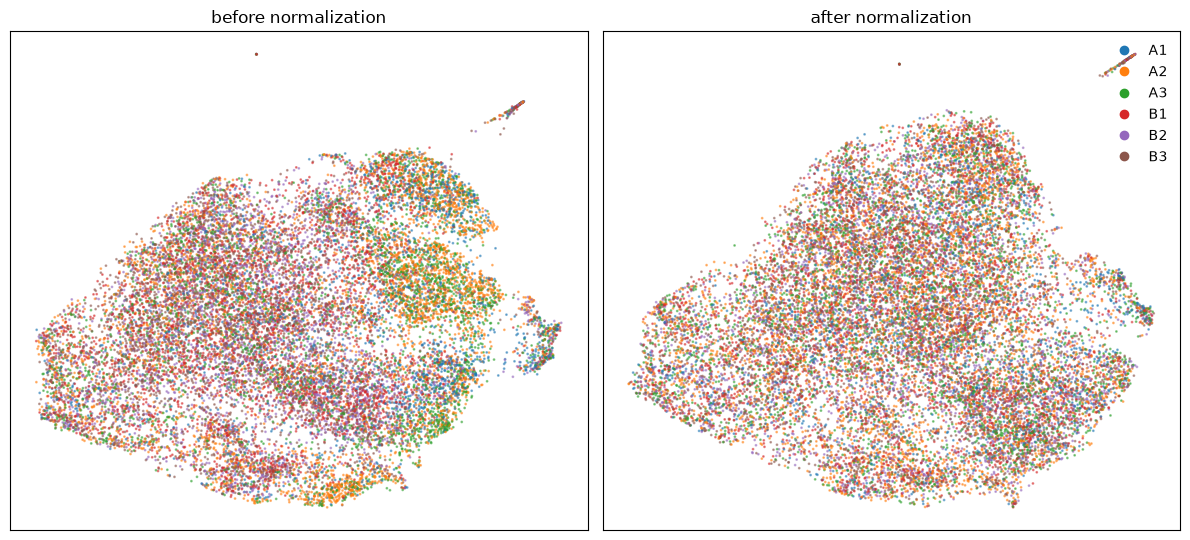

In [12]:
features = before.columns[before.notna().all() & after.notna().all()]


def cell_map(table):
    return umap.UMAP(random_state=0, n_jobs=1).fit_transform(generate_pca_space(table[features]).to_numpy())


wells = cells.get_level_values('Well')
colours = dict(zip(sorted(set(wells)), plt.cm.tab10.colors))
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
for ax, (title, table) in zip(axes, [('before normalization', before), ('after normalization', after)]):
    xy = cell_map(table)
    ax.scatter(xy[:, 0], xy[:, 1], s=1, alpha=0.5, c=[colours[w] for w in wells], rasterized=True)
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])
axes[1].legend(handles=[Line2D([], [], ls='', marker='o', color=c, label=w) for w, c in colours.items()],
               frameon=False, loc='upper right')
plt.tight_layout()
plt.show()

Before normalization, cells from wells A1, A2 and A3 occupy well-specific regions on the right; afterwards the wells are intermixed, and the remaining structure reflects variation shared across wells: the perturbations, and cell states present in every well.

## Archetypes

`chart archetypes` identifies, in each channel, archetypes, the extreme morphological states of the cells, by archetypal analysis, and represents each cell as a convex combination of them: its archetype weights are non-negative and sum to 1. The stage is best run on a compute cluster, so the tutorial uses the weights from the download; the command-line equivalent is `chart archetypes --config chart_tutorial/tutorial.yaml --all-channels`. The weights were computed from the cell table written above and cover the same cells:

In [13]:
archetypes = load_archetypes_config(CONFIG)
schema = archetypes.schema
weights = pd.read_parquet(archetypes.weights_path('Fibrillarin'))
columns = [c for c in weights.columns if c.startswith('Archetype')]
cell_table = pq.read_table(tables['guides'][0], columns=['Well', 'Label']).to_pandas().reset_index()
same = (pd.MultiIndex.from_frame(cell_table[['Well', 'Label']]).sort_values()
        .equals(pd.MultiIndex.from_frame(weights[['Well', 'Label']]).sort_values()))
print(f'{len(weights):,} cells with weights, {len(cell_table):,} in the cell table; the same cells: {same}')
weights.head()

118,612 cells with weights, 118,612 in the cell table; the same cells: True


,Archetype1,Archetype2,Archetype3,Archetype4,Archetype5,Archetype6,Archetype7,Archetype8,Archetype9,Archetype10,Archetype11,Well,Label,Guide,Gene
0,0.000000,0.231875,0.000000,0.000000,0.000000,0.000000,0.000000,0.010134,0.0,0.000000,0.758053,A1,5766,GGTCCCCGATCTTAAAACGG,CRKL
1,0.000000,0.186781,0.000000,0.004845,0.288158,0.173214,0.000000,0.000000,0.0,0.050196,0.296818,A1,9691,GGAACTGAGTGTCCATGTGA,FERMT2
2,0.153384,0.073995,0.143377,0.000000,0.354541,0.214974,0.000000,0.059765,0.0,0.000000,0.000000,A1,15117,AGTTATCAGCCGTGTCGATG,TSC1
3,0.000000,0.000000,0.000000,0.182723,0.067055,0.699873,0.050396,0.000000,0.0,0.000000,0.000000,A1,20614,ATGGGTGGCCAGTGGCTTGG,TIA1
4,0.453326,0.375231,0.000000,0.115356,0.000000,0.000000,0.056129,0.000000,0.0,0.000000,0.000000,A1,43403,GAGTTTCGGATTCATGAGGA,OR2M4


In [14]:
counts = weights.groupby('Gene').size()
is_control = (counts.index == schema.control_gene) | counts.index.str.startswith(schema.control_prefix)
print(f'{(~is_control).sum()} genes, with a median of {counts[~is_control].median():.0f} cells each, '
      f'and {counts[is_control].sum():,} control cells, with non-targeting guides or guides against '
      f'{is_control.sum() - 1} olfactory receptor genes, which these cells do not express')

65 genes, with a median of 1083 cells each, and 33,994 control cells, with non-targeting guides or guides against 10 olfactory receptor genes, which these cells do not express


Empirical cumulative distribution functions (ECDFs) of archetype weight for three knockouts and the NTC controls, each on the Fibrillarin archetype whose mean weight the knockout changes most. Each curve starts at the fraction of cells with zero weight. Knockout cells of the nucleolar protein nucleolin (NCL) are enriched for Archetype10: 29% have zero weight, against 40% of NTC cells. Knockout cells of integrin β5 (ITGB5) are depleted of Archetype11: 59% have zero weight, against 41%. TIA1, a weak-effect gene, is indistinguishable from NTC.

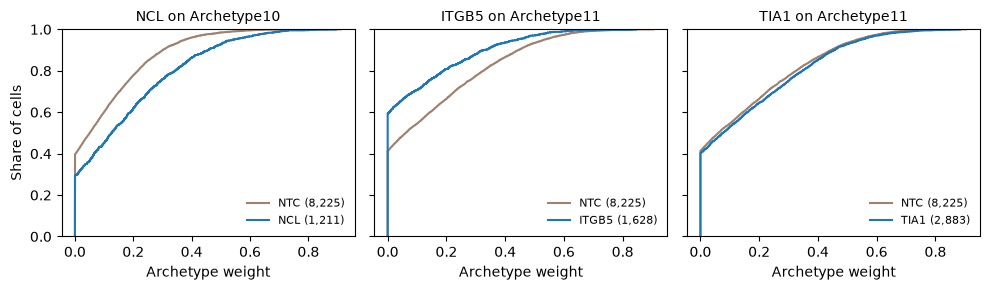

In [15]:
of_ntc = weights.Gene == schema.control_gene
fig, axes = plt.subplots(1, 3, figsize=(10, 3), sharey=True)
for ax, gene in zip(axes, ['NCL', 'ITGB5', 'TIA1']):
    of_gene = weights.Gene == gene
    archetype = (weights.loc[of_gene, columns].mean() - weights.loc[of_ntc, columns].mean()).abs().idxmax()
    ax.ecdf(weights.loc[of_ntc, archetype], color='#9F8170', label=f'NTC ({of_ntc.sum():,})')
    ax.ecdf(weights.loc[of_gene, archetype], color='#1F77B4', label=f'{gene} ({of_gene.sum():,})')
    ax.set_title(f'{gene} on {archetype}', fontsize=10)
    ax.set_xlabel('Archetype weight')
    ax.legend(frameon=False, fontsize=8, loc='lower right')
axes[0].set_ylabel('Share of cells')
plt.tight_layout()
plt.show()

### Representative archetype images

Archetypes are interpreted from images of their most heavily weighted cells. The final step of `chart archetypes`, `crops`, extracts each archetype's ten top-weighted cells, five per grid, in inverted greyscale (darker means more stain), with the cell outline in red and the nucleus in blue. The step requires the images, so its output is included in the download; with images, it is run as `chart archetypes --config chart_tutorial/tutorial.yaml --all-channels --steps crops` once the image locations and channel indices are configured, as described in [Archetypes](archetypes.md). `archetype_total_weights.png` gives each archetype's total weight across all cells. For Fibrillarin:

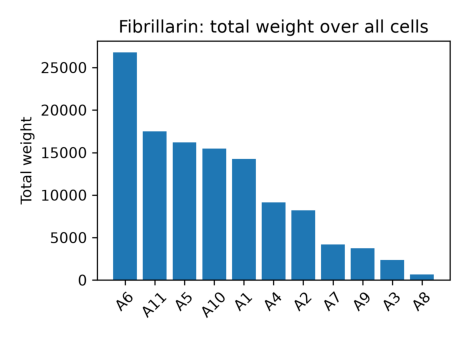

In [16]:
crops = reports / 'archetypes/Fibrillarin'
show_plot(crops / 'archetype_total_weights.png', width=4.5)

The first grid of each Fibrillarin archetype, in decreasing order of total weight. Archetype6, the most abundant, shows the typical pattern of a few nucleoli per nucleus. Most others differ in nucleolar morphology, e.g. several small, separate nucleoli (Archetype11) or a single large, compact nucleolus (Archetype10); others in nuclear shape (curved in Archetype7) or in the absence of nucleoli (Archetype3). Three reflect technical artefacts rather than morphology:

- Archetype4, segmentation error: the cell outlines extend far beyond the nucleus and enclose neighbouring cells. It accounts for 8% of the total weight, so artefacts are not necessarily rare.
- Archetype9, high background: elevated background signal, with uniformly dark nuclei in some crops.
- Archetype8, neighbour contamination: a very bright neighbouring cell at the edge of or within the outline.

Archetype6, 22.6% of the weight, kept


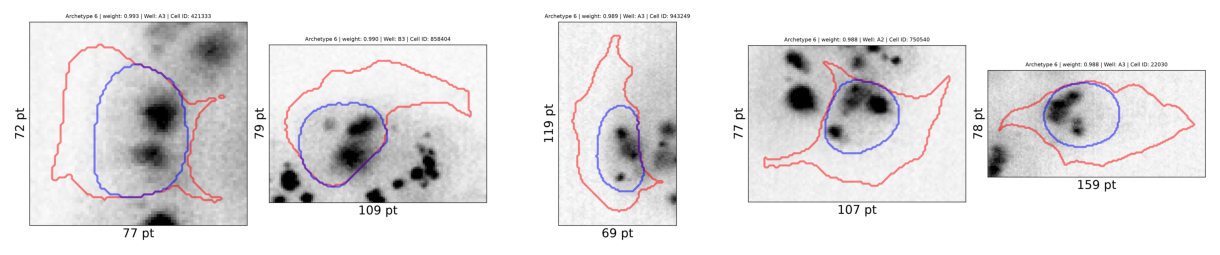

Archetype11, 14.8% of the weight, kept


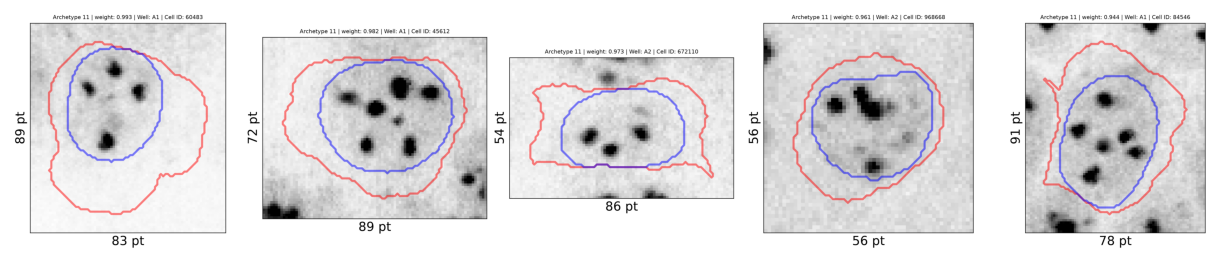

Archetype5, 13.7% of the weight, kept


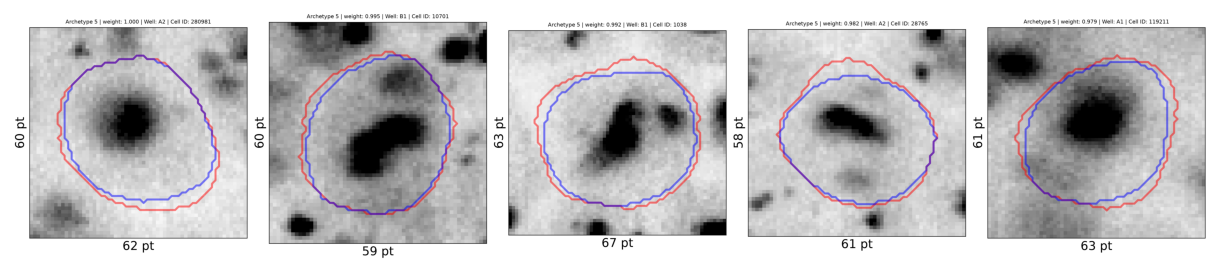

Archetype10, 13.0% of the weight, kept


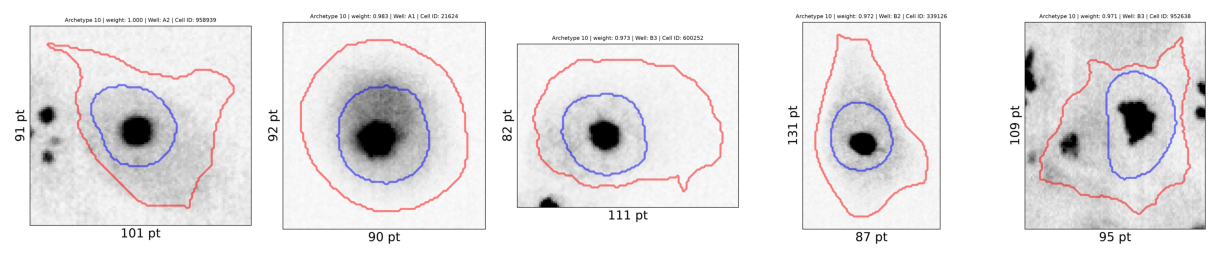

Archetype1, 12.0% of the weight, kept


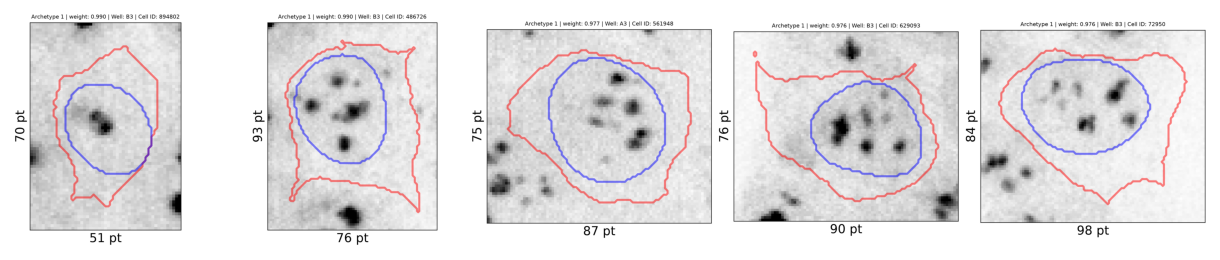

Archetype4, 7.7% of the weight, removed: segmentation error


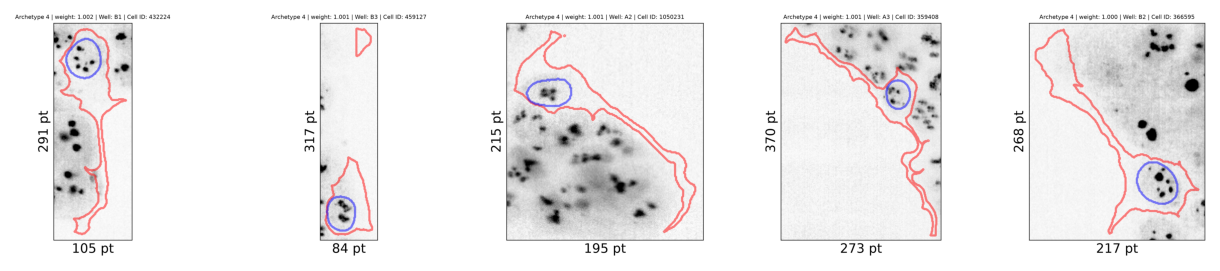

Archetype2, 6.9% of the weight, kept


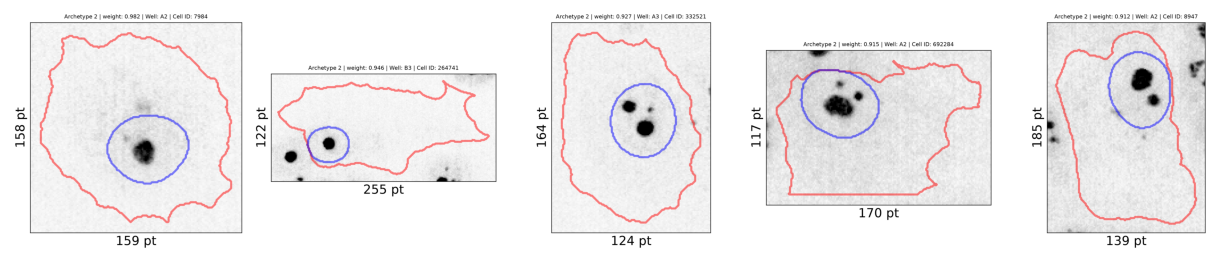

Archetype7, 3.5% of the weight, kept


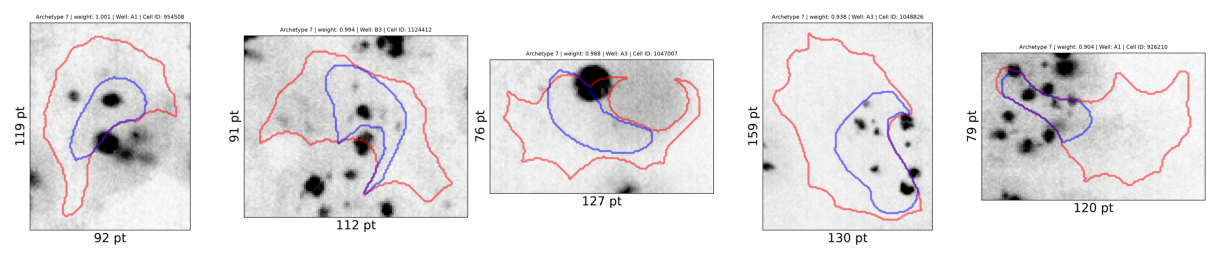

Archetype9, 3.2% of the weight, removed: high background


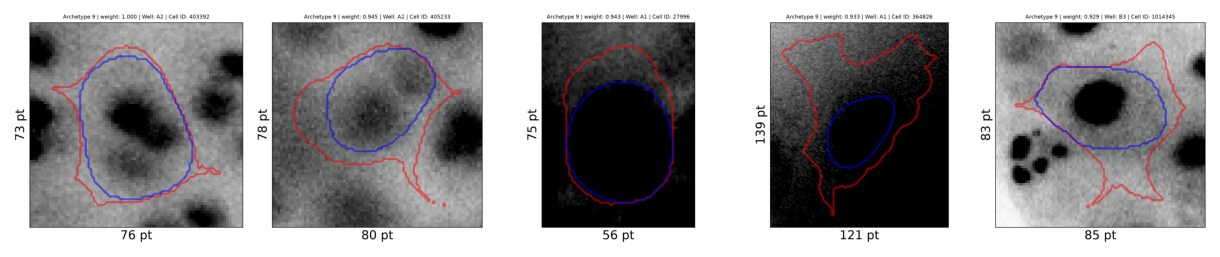

Archetype3, 2.0% of the weight, kept


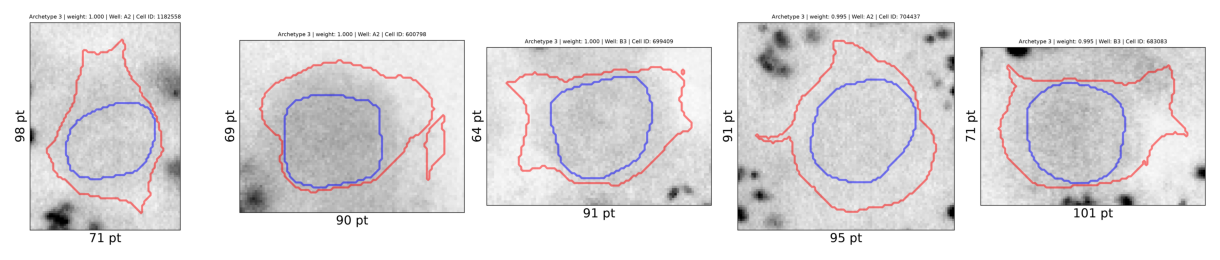

Archetype8, 0.6% of the weight, removed: neighbour contamination


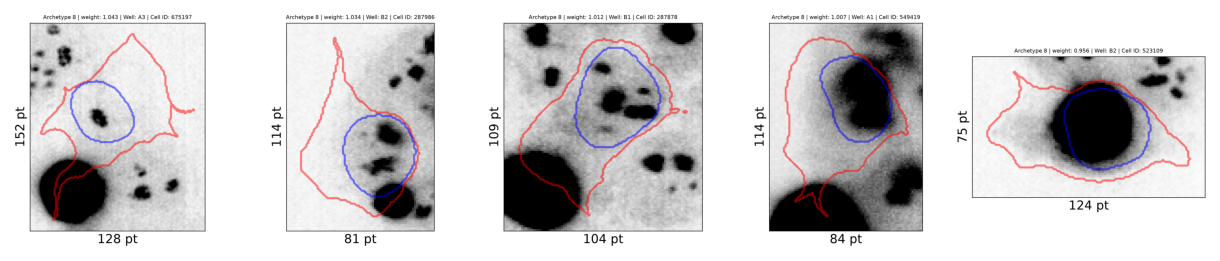

In [17]:
totals = weights[columns].sum().sort_values(ascending=False)
artefacts = {'Archetype4': 'segmentation error', 'Archetype9': 'high background',
             'Archetype8': 'neighbour contamination'}
for archetype, total in totals.items():
    verdict = f'removed: {artefacts[archetype]}' if archetype in artefacts else 'kept'
    print(f'{archetype}, {total / totals.sum():.1%} of the weight, {verdict}')
    show_plot(crops / f'crops/{archetype.lower()}_Fibrillarin_grid_1.png', width=12)

The crops of the other channels are included in the download, in `chart_tutorial/reports/archetypes/<channel>/crops/`; to generate crops for your own screen, see [Archetypes](archetypes.md).

### Review

Archetypes that reflect imaging or segmentation artefacts should be excluded before testing. They are listed under `archetypes.archetypes_to_remove`, grouped under labels of your choice. Reviewing every channel's crops in this way gives, for the tutorial:

In [18]:
config['archetypes']['archetypes_to_remove'] = {
    'segmentation_error': ['DAPI1_Archetype5', 'DAPI1_Archetype6', 'Fibrillarin_Archetype4',
                           'rpS6_Archetype1', 'TOM20_Archetype4'],
    'neighbour_contamination': ['Fibrillarin_Archetype8', 'rpS6_Archetype4'],
    'high_background': ['DAPI1_Archetype8', 'Fibrillarin_Archetype9'],
}
save_config()

`chart effects` skips these archetypes. They remain part of each cell's weights, so the tests of the other archetypes are unchanged, but since all tests are corrected jointly, their q-values change. `top_cells.parquet`, next to the grids, gives the well of each cell shown, which reveals archetypes drawn from a single well.

### Annotation

`chart annotation` uses a multimodal language model to describe each retained archetype from its crops: a morphological description, a comparison with the channel's normal archetype, three proposed names and a functional hypothesis. The normal archetype is the most abundant retained one unless `annotation.normal_archetypes` specifies others. **The step is optional.** It requires `pip install ".[annotation]"` and an API key for a model provider (see [Installation](installation.md)), and takes about 45 minutes, so its output for the tutorial is included in the download. To regenerate it, set `RUN_ANNOTATION = True`; the command-line equivalent is `chart annotation --config chart_tutorial/tutorial.yaml --all-channels`. See [Annotation](annotation.md) for details.

In [19]:
RUN_ANNOTATION = False   # True needs the annotation extra and a model key

if RUN_ANNOTATION:
    run_annotation(CONFIG)

The per-archetype reports are in `annotation/<channel>/archetype_reviews/` under `local_output_dir`, and each channel's reports are combined in `combined_archetype_final.md`. The first proposed name for each Fibrillarin archetype:

In [20]:
reviews = reports / 'annotation/Fibrillarin/archetype_reviews'
names = {}
for report in (reviews / 'combined_archetype_final.md').read_text().split('\n## ')[1:]:
    title, body = report.split('\n', 1)
    names[title] = body.split('### Proposed Names:\n', 1)[1].splitlines()[0].removeprefix('1. ')
pd.Series(names, name='first proposed name').to_frame()

,first proposed name
Archetype 1,Multifocal Nuclear Fibrillarin
Archetype 2,Clumped Nucleolar Fibrillarin
Archetype 3,Weak Diffuse Mixed Fibrillarin
Archetype 5,Clumped Nuclear Fibrillarin Foci
Archetype 6,Coarse Punctate Nuclear Fibrillarin
Archetype 7,Mixed Nuclear–Cytoplasmic Fibrillarin Clumps
Archetype 10,Compact Nucleolar Focus
Archetype 11,Clustered Nuclear Fibrillarin Puncta


The names are drafts and should be checked against the crops. For example, the report on Archetype5 describes its cells accurately (small and round, with the nucleus filling the cell and fibrillarin in coarse clumps), but neither the report nor the names identify them as most likely mitotic. The full report on Archetype10, which is enriched in NCL knockout cells:

In [21]:
print((reviews / 'archetype10_final.md').read_text())

### Summary:
Archetype 10 shows predominantly very strong Fibrillarin-associated signal, but with heterogeneous intensity and distribution across cells. The dominant pattern is a compact, dense, rounded to irregular clumped focus within the nuclear boundary, typically appearing as a single prominent intranuclear aggregate. Surrounding nuclear signal is much weaker, sometimes diffuse or finely granular, and cytoplasmic staining is generally minimal. One cell shows additional extranuclear/cytoplasmic punctate-to-clumped signal, indicating occasional mixed nuclear and cytoplasmic localization.

Compared with the normal baseline, staining is less uniformly centralized and more patchy or aggregated, with stronger localized dark foci rather than a consistent compact nuclear/perinuclear pattern. Cell sizes are variable, including elongated or spread morphologies, and nuclei also vary in size, appearing relatively large in some cells. Cell outlines are more irregular than baseline, including p

## Effects

`chart effects` compares, for each archetype, the cells of each perturbation with the control cells from the same wells. The effect size is the Wasserstein-1 distance between the two distributions of CLR-transformed archetype weight, signed by the difference in medians (`signed_w1`). P-values are obtained by permuting perturbation and control labels within wells, and are corrected across all channels by Benjamini–Hochberg. See [Effects](effects.md) for details. The run takes about 6 minutes on 8 cores; the command-line equivalent is `chart effects --config chart_tutorial/tutorial.yaml --all-channels`.

`effects/pooled.parquet` contains every test; below are the number of significant tests and the ten strongest effects.

In [22]:
outputs = run_effects(CONFIG)

In [23]:
effects = load_table(load_effects_config(CONFIG).outputs_path, 'pooled')
significant = effects[effects.qval < 0.01]
print(f'{len(significant):,} of {len(effects):,} tests have a q-value below 0.01, on '
      f'{significant.Gene.nunique()} genes and {significant.Archetype.nunique()} archetypes')
strongest = significant.signed_w1.abs().sort_values(ascending=False).index
significant.loc[strongest, ['Gene', 'Archetype', 'signed_w1', 'pval', 'qval', 'n_gene']].head(10)

1,175 of 2,275 tests have a q-value below 0.01, on 65 genes and 35 archetypes


,Gene,Archetype,signed_w1,pval,qval,n_gene
1272,MTOR,rpS6_Archetype10,-3.532803,0.001996,0.004132,1787
351,RPL14,DAPI1_Archetype11,3.395431,0.001996,0.004132,880
375,RPL32,DAPI1_Archetype11,3.182863,0.001996,0.004132,524
2145,RPS6,TOM20_Archetype1,-3.069672,0.001996,0.004132,455
359,RPL18,DAPI1_Archetype11,3.029024,0.001996,0.004132,482
1299,PDPK1,rpS6_Archetype10,-2.969046,0.001996,0.004132,838
2135,RPS4X,TOM20_Archetype1,-2.954905,0.001996,0.004132,521
2115,RPS11,TOM20_Archetype1,-2.932385,0.001996,0.004132,394
1888,NCKAP1,TOM20_Archetype5,2.886737,0.001996,0.004132,1580
566,ATP6V0D1,Fibrillarin_Archetype10,2.865460,0.001996,0.004132,1645


Volcano plot for Fibrillarin Archetype11, characterized by several small, separate nucleoli (its top-weighted cell is shown on the right). `Up` and `Down` perturbations significantly increase or decrease the archetype's weight relative to controls; `NS` perturbations are not significant (q ≥ 0.01, below the dashed line). The three strongest effects in each direction are labelled. With 500 permutations, p-values cannot fall below 1/501, so the significant perturbations accumulate at the top of the plot and are distinguished by effect size.

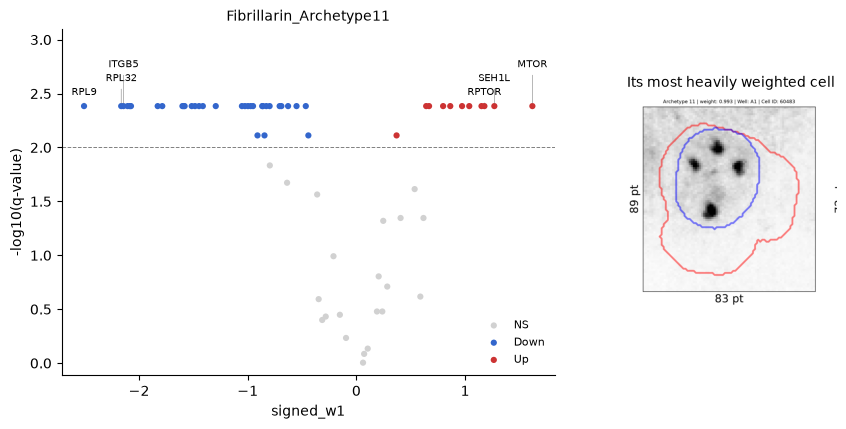

In [24]:
archetype = 'Fibrillarin_Archetype11'
channel, column = archetype.rsplit('_', 1)
volcano = effects[effects.Archetype == archetype].set_index('Gene')
neg_log10_q = -np.log10(volcano.qval)
category = pd.Series('NS', index=volcano.index)
category[(volcano.qval < 0.01) & (volcano.signed_w1 > 0)] = 'Up'
category[(volcano.qval < 0.01) & (volcano.signed_w1 < 0)] = 'Down'

fig, (ax, ax_cell) = plt.subplots(1, 2, figsize=(10, 4.5), width_ratios=[7, 3])
for name, colour in [('NS', (0.82, 0.82, 0.82)), ('Down', (0.2, 0.4, 0.8)), ('Up', (0.8, 0.2, 0.2))]:
    mask = category == name
    ax.scatter(volcano.signed_w1[mask], neg_log10_q[mask], color=colour, s=20, edgecolors='none', label=name)
ax.axhline(-np.log10(0.01), color='grey', ls='--', lw=0.7)
for name, sign in [('Up', 1), ('Down', -1)]:
    labelled = volcano.signed_w1[(sign * volcano.signed_w1)[category == name].nlargest(3).index].sort_values()
    for level, gene in enumerate(labelled.index):
        ax.annotate(gene, (volcano.signed_w1[gene], neg_log10_q[gene]), xytext=(0, 8 + 10 * level),
                    textcoords='offset points', ha='center', fontsize=7,
                    arrowprops=dict(arrowstyle='-', color='grey', lw=0.4))
ax.set_ylim(top=neg_log10_q.max() * 1.3)
ax.set_xlabel('signed_w1')
ax.set_ylabel('-log10(q-value)')
ax.set_title(archetype, fontsize=10)
ax.legend(frameon=False, fontsize=8, loc='lower right')
ax.spines[['top', 'right']].set_visible(False)
grid = plt.imread(reports / f'archetypes/{channel}/crops/{column.lower()}_{channel}_grid_1.png')
ax_cell.imshow(grid[:, :grid.shape[1] // 5])
ax_cell.set_axis_off()
ax_cell.set_title('Its most heavily weighted cell', fontsize=10)
plt.show()

Significant effects (q < 0.01) of all perturbations on all archetypes, positive where the archetype's weight increases relative to controls. Rows and columns are hierarchically clustered; the blocks of genes anticipate the modules below.

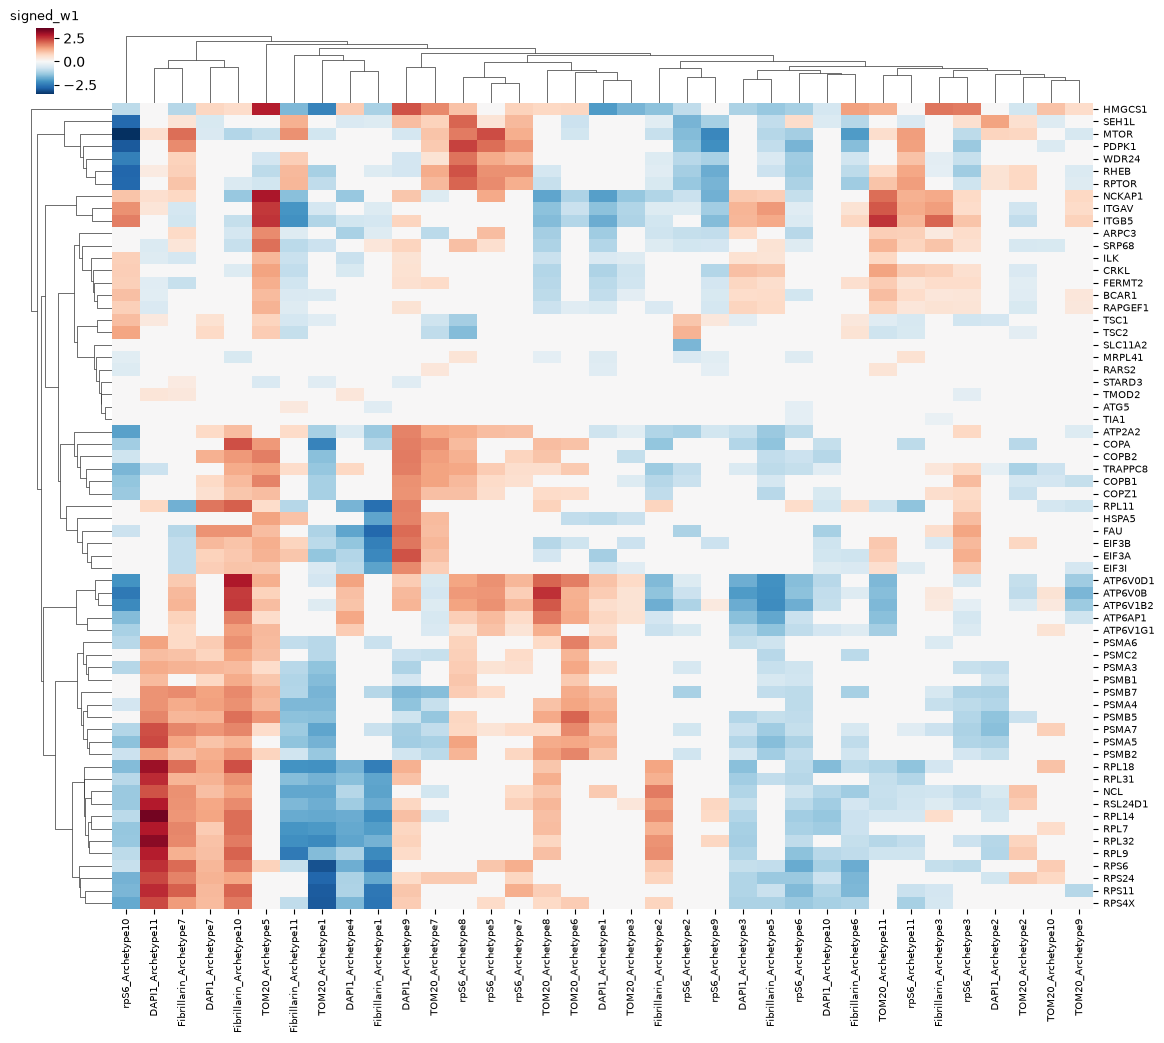

In [25]:
signed = effects.signed_w1.where(effects.qval < 0.01, 0)
grid = effects.assign(effect=signed).pivot(index='Gene', columns='Archetype', values='effect')
grid = grid.loc[(grid != 0).any(axis=1), (grid != 0).any(axis=0)]
limit = np.abs(grid.to_numpy()).max()
cluster = sns.clustermap(grid, cmap='RdBu_r', center=0, vmin=-limit, vmax=limit, figsize=(12, 11),
                         xticklabels=True, yticklabels=True, dendrogram_ratio=0.08,
                         cbar_pos=(0.02, 0.93, 0.015, 0.06))
cluster.ax_cbar.set_title('signed_w1', fontsize=9)
cluster.ax_heatmap.tick_params(labelsize=7)
cluster.ax_heatmap.set_xlabel('')
cluster.ax_heatmap.set_ylabel('')
plt.show()

## Programs

`chart programs` decomposes the significant effects into morphological programs: sparse sets of archetypes, spanning channels, that perturbations shift together. It runs in four steps:

1. `matrix` assembles the significant effects into a gene × archetype matrix.
2. `fit` estimates the programs by sparse PCA.
3. `modules` groups the genes into modules by consensus clustering over 150 refits on subsamples of the genes.
4. `cells` scores every cell on the programs.

See [Programs](programs.md) for details. Two parameters must be chosen: the number of programs and the number of modules. The defaults, 18 and 25, are those of the published analysis of 471 genes. Neither has a closed-form criterion; below, both are chosen from diagnostics, as in the published analysis. Each run below corresponds to `chart programs --config chart_tutorial/tutorial.yaml --steps ...` with the same steps.

In [26]:
outputs = run_programs(CONFIG, steps=['matrix'])
directory = load_programs_config(CONFIG).outputs_path
matrix = load_table(directory, 'matrix')
print(f'{matrix.shape[0]} genes by {matrix.shape[1]} archetypes')

65 genes by 35 archetypes


### Choosing program numbers

Additional programs explain more of the effects with diminishing returns, and programs supported by few genes may not be reproducible. Below, for 2 to 12 programs: the fraction of the effect matrix left unexplained (relative residual sum of squares), and the stability of the programs, the mean cosine similarity between the loadings of the full fit and of five refits on 85% of the genes (1 means identical programs). This takes about a minute.

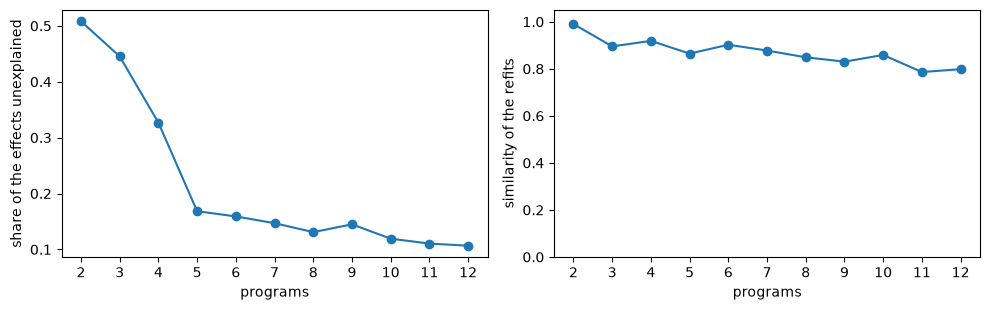

In [27]:
seed = load_programs_config(CONFIG).seed
X = matrix.to_numpy()
rng = np.random.default_rng(seed)
choices = {}
for k in range(2, 13):
    loadings, scores = fit_programs(matrix, k, seed, N_JOBS)
    L = loadings.to_numpy()
    similarity = []
    for refit in range(5):
        genes = np.sort(rng.choice(len(matrix), int(0.85 * len(matrix)), replace=False))
        refitted, _ = fit_programs(matrix.iloc[genes], k, seed + refit + 1, N_JOBS)
        order, signs = align_to_reference(refitted.to_numpy(), L)
        R = refitted.to_numpy()[:, order] * signs
        similarity.append(np.mean((L * R).sum(axis=0) / (np.linalg.norm(L, axis=0) * np.linalg.norm(R, axis=0))))
    choices[k] = {'unexplained': ((X - scores.to_numpy() @ L.T) ** 2).sum() / (X ** 2).sum(),
                  'similarity': np.mean(similarity)}
choices = pd.DataFrame(choices).T

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, (name, label) in zip(axes, [('unexplained', 'share of the effects unexplained'),
                                     ('similarity', 'similarity of the refits')]):
    ax.plot(choices.index, choices[name], marker='o')
    ax.set_xlabel('programs')
    ax.set_ylabel(label)
    ax.set_xticks(choices.index)
axes[1].set_ylim(0, 1.05)
plt.tight_layout()
plt.show()

The unexplained fraction drops steeply up to 5 programs, from 0.51 to 0.17, and by only one to two percentage points per additional program thereafter. Stability stays between 0.8 and 0.9 throughout and therefore does not constrain the choice. Here we will use 5 programs.

The number of modules only sets where the final tree is cut; the consensus matrix, the frequency with which each pair of genes co-clusters across refits, does not depend on it. The first run therefore keeps the default of 25, and the number is chosen from the consensus below. The refits take about 2 minutes.

In [28]:
config['programs'] = {'k': 5}
save_config()
outputs = run_programs(CONFIG, steps=['fit', 'modules'])

### Choosing module numbers

Modules are obtained by average-linkage hierarchical clustering of 1 − consensus, with the dendrogram cut into the chosen number of clusters. The dendrogram is shown below; the height at which two branches merge is 1 − their average co-clustering frequency.

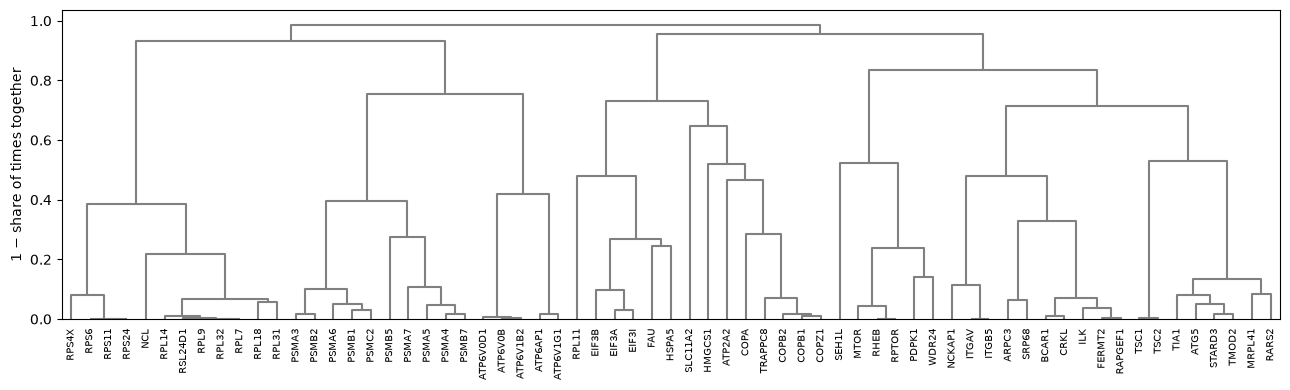

In [29]:
consensus = load_table(directory, 'consensus')
distance = np.clip(1 - consensus.to_numpy(), 0, None)
np.fill_diagonal(distance, 0)
tree = linkage(squareform(distance, checks=False), method='average')

fig, ax = plt.subplots(figsize=(13, 4))
dendrogram(tree, labels=list(consensus.index), ax=ax, color_threshold=0, above_threshold_color='grey',
           leaf_font_size=7)
ax.set_ylabel('1 − share of times together')
plt.tight_layout()
plt.show()

Here we will cut the tree into 8 branches. The modules step is then rerun: its seeded refits reproduce the same consensus, which is now cut into 8 modules, and the cells step scores the cells.

In [30]:
config['programs']['n_modules'] = 8
save_config()
outputs = run_programs(CONFIG, steps=['modules', 'cells'])

The outputs are in `programs/` under `data_output_dir`.

| Table | One row per | Holds |
|---|---|---|
| `matrix.parquet` | gene | its signed effect on each archetype, for the genes and archetypes with a q-value below 0.01 |
| `loadings.parquet` | archetype | its loading on each program |
| `scores.parquet` | gene | its score on each program |
| `consensus.parquet` | gene | its co-clustering frequency with every other gene across the refits |
| `modules.parquet` | gene | its module assignment and membership margin |
| `cell_scores.parquet` | cell | its score on each program |
| `top_cells.parquet` | program and rank | example cells and their bounding boxes in the images |

In [31]:
loadings, scores, consensus, modules = (load_table(directory, name) for name in
                                        ('loadings', 'scores', 'consensus', 'modules'))
programs = list(loadings.columns)

## Program interpretation

Each program has non-zero loadings on a few archetypes, often from several channels: positive for archetypes whose weight increases in its high-scoring perturbations, negative for those whose weight decreases. Below, archetypes are grouped by the program on which they load most strongly, and ordered by sign, then by magnitude.

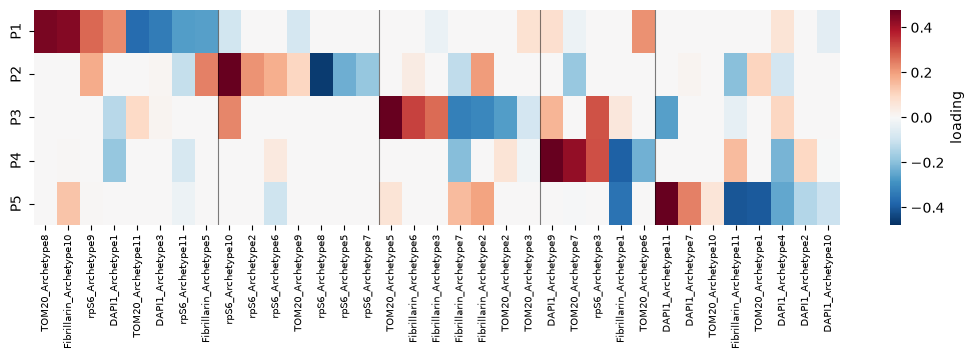

In [32]:
strongest = np.abs(loadings.to_numpy()).argmax(axis=1)
peak = loadings.to_numpy()[np.arange(len(loadings)), strongest]
ordered = loadings.iloc[np.lexsort((-np.abs(peak), -np.sign(peak), strongest))]
limit = np.percentile(np.abs(loadings.to_numpy()), 98)
fig, ax = plt.subplots(figsize=(13, 2.8))
sns.heatmap(ordered.T, ax=ax, cmap='RdBu_r', center=0, vmin=-limit, vmax=limit, xticklabels=True,
            cbar_kws={'label': 'loading'})
for edge in np.flatnonzero(np.diff(np.sort(strongest))) + 1:
    ax.axvline(edge, color='black', lw=0.8, alpha=0.5)
ax.tick_params(axis='x', labelsize=7)
ax.set_xlabel('')
plt.show()

The largest loadings of each program, and its highest- and lowest-scoring genes.

In [33]:
def largest(series, n):
    series = series[series != 0]
    return ', '.join(f'{name} {value:+.2f}' for name, value in
                     series.sort_values(key=np.abs, ascending=False).head(n).items())

pd.DataFrame({'largest loadings': {p: largest(loadings[p], 4) for p in programs},
              'highest genes': {p: ', '.join(scores[p].nlargest(4).index) for p in programs},
              'lowest genes': {p: ', '.join(scores[p].nsmallest(4).index) for p in programs}})

,largest loadings,highest genes,lowest genes
P1,"TOM20_Archetype8 +0.46, Fibrillarin_Archetype10 +0.44, TOM20_Archetype11 -0.37, DAPI1_Archetype3 -0.34","ATP6V0B, ATP6V0D1, ATP6V1B2, ATP6AP1","NCKAP1, ITGB5, ITGAV, CRKL"
P2,"rpS6_Archetype10 +0.60, rpS6_Archetype8 -0.46, Fibrillarin_Archetype5 +0.24, rpS6_Archetype5 -0.23","TSC2, TSC1, RPL11, ILK","MTOR, PDPK1, RHEB, RPTOR"
P3,"TOM20_Archetype5 +0.50, Fibrillarin_Archetype6 +0.33, Fibrillarin_Archetype7 -0.33, Fibrillarin_Archetype2 -0.31","HMGCS1, ITGB5, ITGAV, NCKAP1","MTOR, NCL, RPS24, RHEB"
P4,"DAPI1_Archetype9 +0.59, TOM20_Archetype7 +0.42, Fibrillarin_Archetype1 -0.39, rpS6_Archetype3 +0.31","EIF3A, EIF3B, FAU, HSPA5","PSMB5, PSMB7, PSMA5, PSMA4"
P5,"DAPI1_Archetype11 +0.54, Fibrillarin_Archetype11 -0.41, TOM20_Archetype1 -0.40, Fibrillarin_Archetype1 -0.35","RPL14, RPL18, RPS6, RPL32","SEH1L, MTOR, WDR24, RPTOR"


## Modules

The consensus matrix, ordered by module. Modules appear as blocks along the diagonal, some with internal structure: within the ribosome module, the small-subunit proteins (RPS) form a sub-block.

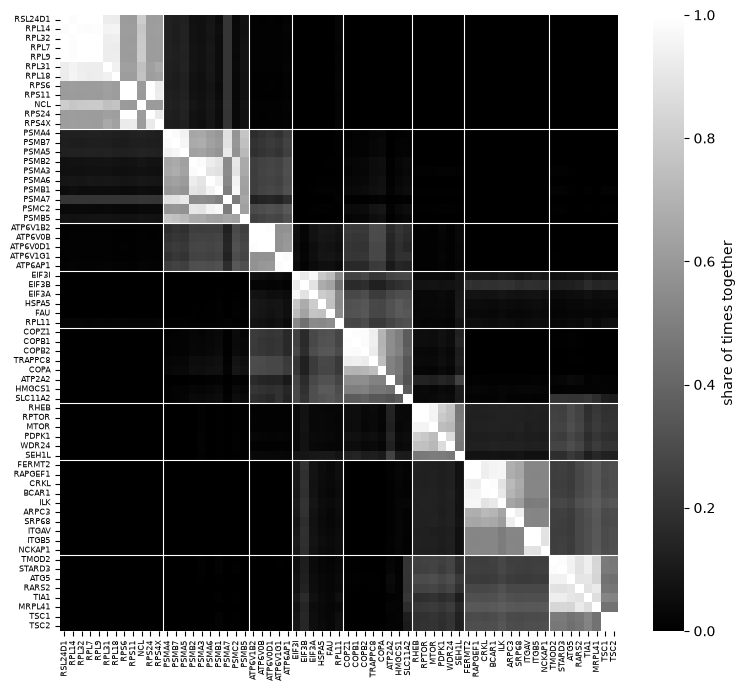

In [34]:
order = modules.sort_values(['module', 'margin'], ascending=[True, False]).index
fig, ax = plt.subplots(figsize=(9, 8))
sns.heatmap(consensus.loc[order, order], ax=ax, cmap='gray', vmin=0, vmax=1,
            xticklabels=True, yticklabels=True, cbar_kws={'label': 'share of times together'})
for edge in np.cumsum(modules.module.value_counts().sort_index().to_numpy())[:-1]:
    ax.axhline(edge, color='white', lw=0.8)
    ax.axvline(edge, color='white', lw=0.8)
ax.tick_params(labelsize=6)
ax.set_xlabel('')
ax.set_ylabel('')
plt.show()

The genes of each module, in decreasing order of membership margin, with each module named after the shared function of its genes. A gene's `margin` in `modules.parquet` is its mean co-clustering frequency with its own module minus its highest with any other module.

In [35]:
named = {'PSMA4': 'Proteasome', 'RPL7': 'Ribosome', 'ATP6V0D1': 'V-ATPase', 'COPA': 'Golgi traffic',
         'EIF3A': 'Translation initiation', 'MTOR': 'mTOR signalling', 'ITGB5': 'Integrin adhesion',
         'TIA1': 'Weak effects'}
module_names = {modules.module[gene]: name for gene, name in named.items()}
for module, members in modules.sort_values('margin', ascending=False).groupby('module'):
    print(f'{module_names[module]}: {", ".join(members.index)}')

Ribosome: RSL24D1, RPL14, RPL32, RPL7, RPL9, RPL31, RPL18, RPS6, RPS11, NCL, RPS24, RPS4X
Proteasome: PSMA4, PSMB7, PSMA5, PSMB2, PSMA3, PSMA6, PSMB1, PSMA7, PSMC2, PSMB5
V-ATPase: ATP6V1B2, ATP6V0B, ATP6V0D1, ATP6V1G1, ATP6AP1
Translation initiation: EIF3I, EIF3B, EIF3A, HSPA5, FAU, RPL11
Golgi traffic: COPZ1, COPB1, COPB2, TRAPPC8, COPA, ATP2A2, HMGCS1, SLC11A2
mTOR signalling: RHEB, RPTOR, MTOR, PDPK1, WDR24, SEH1L
Integrin adhesion: FERMT2, RAPGEF1, CRKL, BCAR1, ILK, ARPC3, SRP68, ITGAV, ITGB5, NCKAP1
Weak effects: TMOD2, STARD3, ATG5, RARS2, TIA1, MRPL41, TSC1, TSC2


The modules group functionally related genes: proteasome subunits (PSMA, PSMB), ribosomal proteins (RPL, RPS), the lysosomal V-ATPase (ATP6V), the COPI coat (COPA, COPB, COPZ1), translation initiation factor eIF3 (EIF3), mTORC1 and its activators (MTOR, RPTOR, RHEB, PDPK1, WDR24, SEH1L), and integrin adhesion (ITGAV, ITGB5, ILK). Six of the seven weak-effect genes, which share no function, form a separate module together with the mTORC1 inhibitors TSC1 and TSC2; the seventh, SLC11A2, and the cholesterol-synthesis enzyme HMGCS1 are only loosely assigned to the Golgi module.

Gene × program scores, displayed as in the published analysis: genes in the order of the module dendrogram, with their modules annotated above, and programs ordered by hierarchical clustering of their score profiles across genes.

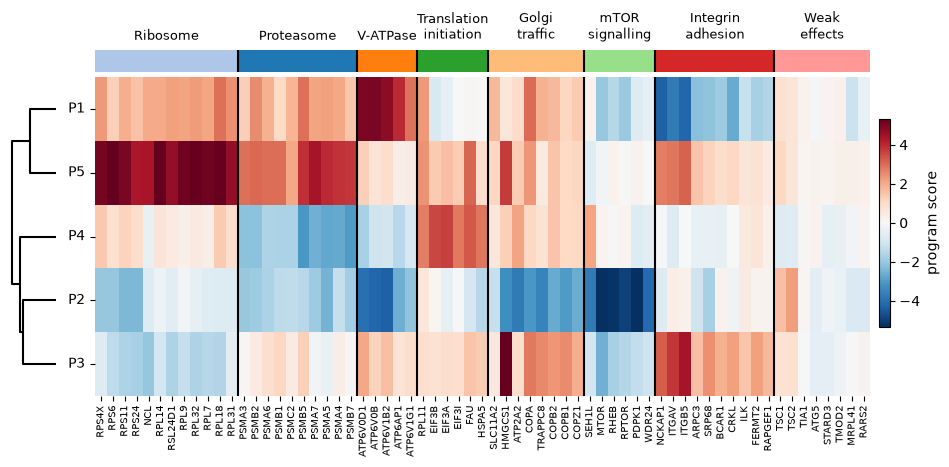

In [36]:
genes = consensus.index[leaves_list(tree)]
program_tree = linkage(pdist(scores.T.to_numpy(), metric='correlation'), method='average')
grid = scores.loc[genes, scores.columns[leaves_list(program_tree)]].T
module_of = modules.module[genes].to_numpy()
palette = dict(zip(module_names, sns.color_palette('tab20')))
edges = np.flatnonzero(module_of[1:] != module_of[:-1]) + 1
limit = np.percentile(np.abs(grid.to_numpy()), 98)

fig, ((corner, strip), (branches, ax)) = plt.subplots(
    2, 2, figsize=(13, 4.5), height_ratios=[0.07, 1], width_ratios=[0.05, 1],
    gridspec_kw={'hspace': 0.03, 'wspace': 0.08})
corner.set_axis_off()
dendrogram(program_tree, orientation='left', no_labels=True, color_threshold=0,
           above_threshold_color='black', ax=branches)
branches.invert_yaxis()
branches.set_axis_off()
sns.heatmap(grid, ax=ax, cmap='RdBu_r', center=0, vmin=-limit, vmax=limit, xticklabels=True, cbar=False)
for i, module in enumerate(module_of):
    strip.axvspan(i, i + 1, color=palette[module])
for module in palette:
    strip.text(np.flatnonzero(module_of == module).mean() + 0.5, 1.3, module_names[module].replace(' ', '\n'),
               ha='center', va='bottom', fontsize=9)
for edge in edges:
    strip.axvline(edge, color='black', lw=1.5)
    ax.axvline(edge, color='black', lw=1.5)
strip.set_xlim(0, len(genes))
strip.set_axis_off()
ax.tick_params(axis='x', labelsize=7)
ax.tick_params(axis='y', rotation=0)
ax.set_xlabel('')
fig.colorbar(ax.collections[0], ax=[strip, ax], shrink=0.6, pad=0.01, label='program score')
plt.show()

## A closer look at one program

Any program can be examined in detail by setting `PROGRAM` below. P2 captures mTORC1 signalling. Knockouts of the mTORC1 activators MTOR, PDPK1, RHEB and RPTOR score lowest: their cells show less rpS6 Archetype10 (strong, uniform rpS6 staining) and more rpS6 Archetype8 (weak staining) and Fibrillarin Archetype11 (several small, separate nucleoli). Knockouts of the mTORC1 inhibitors TSC1 and TSC2 score highest. The program corresponds to P5 of the published analysis.

The loadings of the program: positive for archetypes enriched in its high-scoring perturbations, negative for those depleted.

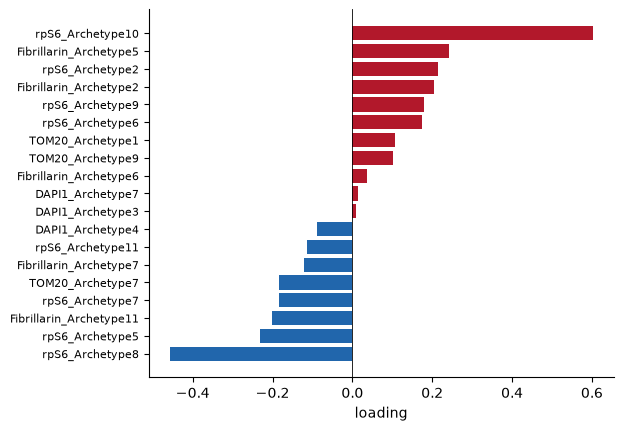

In [37]:
PROGRAM = 'P2'

program_loadings = loadings[PROGRAM][loadings[PROGRAM] != 0].sort_values()
fig, ax = plt.subplots(figsize=(6, 0.22 * len(program_loadings) + 0.6))
ax.barh(program_loadings.index, program_loadings, color=np.where(program_loadings > 0, '#B2182B', '#2166AC'))
ax.axvline(0, color='black', lw=0.6)
ax.set_xlabel('loading')
ax.tick_params(axis='y', labelsize=8)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

The top-weighted cell of each of the three archetypes with the largest positive (top row) and negative (bottom row) loadings. The full grids are in `reports/archetypes/<channel>/crops/`.

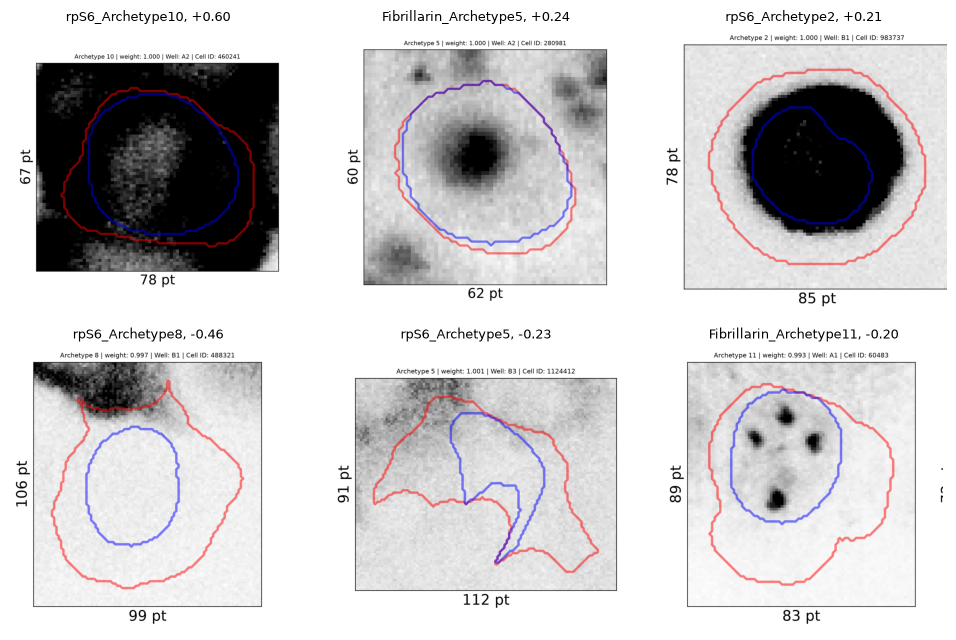

In [38]:
sides = [program_loadings[program_loadings > 0].nlargest(3), program_loadings[program_loadings < 0].nsmallest(3)]
fig, axes = plt.subplots(2, 3, figsize=(10, 6.5))
for row, side in zip(axes, sides):
    for ax, (archetype, loading) in zip(row, side.items()):
        channel, column = archetype.rsplit('_', 1)
        image = plt.imread(reports / f'archetypes/{channel}/crops/{column.lower()}_{channel}_grid_1.png')
        ax.imshow(image[:, :image.shape[1] // 5])
        ax.set_title(f'{archetype}, {loading:+.2f}', fontsize=9)
    for ax in row:
        ax.set_axis_off()
plt.tight_layout()
plt.show()

The scores of all genes on the program, coloured by module. Most genes score negatively on P2; the V-ATPase genes, required for amino-acid sensing by mTORC1, score nearly as low as the mTORC1 module. Only TSC1 and TSC2 score clearly positive.

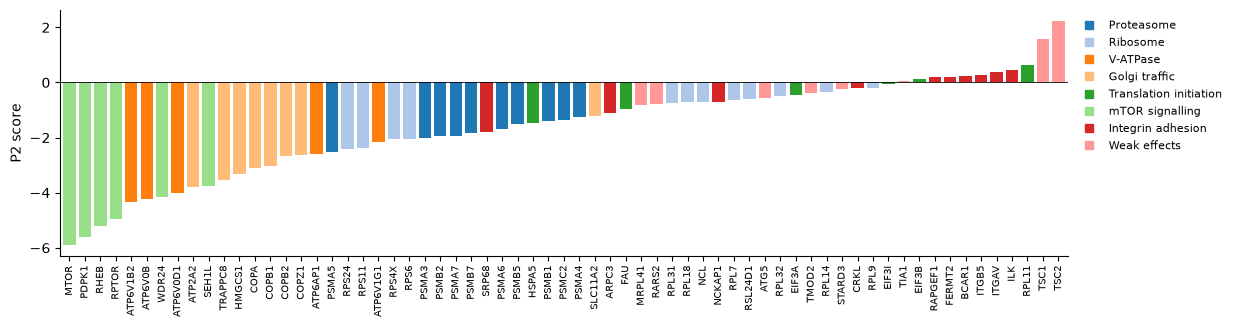

In [39]:
gene_scores = scores[PROGRAM].sort_values()
fig, ax = plt.subplots(figsize=(13, 3.2))
ax.bar(gene_scores.index, gene_scores, color=[palette[modules.module[gene]] for gene in gene_scores.index])
ax.axhline(0, color='black', lw=0.6)
ax.set_ylabel(f'{PROGRAM} score')
ax.tick_params(axis='x', rotation=90, labelsize=7)
ax.set_xlim(-0.6, len(gene_scores) - 0.4)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(handles=[Line2D([], [], ls='', marker='s', color=palette[module], label=module_names[module])
                   for module in palette], frameon=False, fontsize=8, loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

The `cells` step also scores every cell on each program (`cell_scores.parquet`), which shows how a perturbation shifts the distribution of its cells rather than only their mean. Below, ECDFs of the cell scores for the two lowest- and two highest-scoring genes, and for the NTC cells.

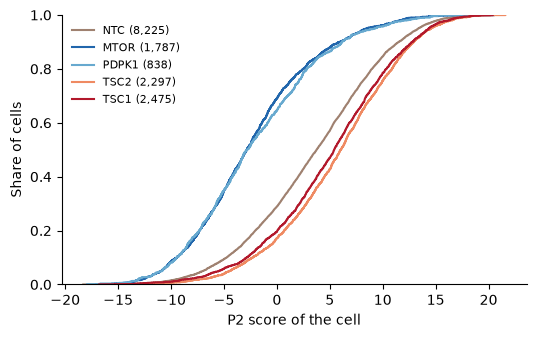

MTOR: 16% of its cells score above the median NTC cell
PDPK1: 16% of its cells score above the median NTC cell
TSC2: 64% of its cells score above the median NTC cell
TSC1: 60% of its cells score above the median NTC cell


In [40]:
cell_scores = load_table(directory, 'cell_scores')
of_ntc = cell_scores.Gene == schema.control_gene
shown = [*scores[PROGRAM].nsmallest(2).index, *scores[PROGRAM].nlargest(2).index]
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.ecdf(cell_scores.loc[of_ntc, PROGRAM], color='#9F8170', label=f'NTC ({of_ntc.sum():,})')
for gene, colour in zip(shown, ['#2166AC', '#67A9CF', '#EF8A62', '#B2182B']):
    of_gene = cell_scores.Gene == gene
    ax.ecdf(cell_scores.loc[of_gene, PROGRAM], color=colour, label=f'{gene} ({of_gene.sum():,})')
ax.set_xlabel(f'{PROGRAM} score of the cell')
ax.set_ylabel('Share of cells')
ax.legend(frameon=False, fontsize=8)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

median = cell_scores.loc[of_ntc, PROGRAM].median()
for gene in shown:
    share = (cell_scores.loc[cell_scores.Gene == gene, PROGRAM] > median).mean()
    print(f'{gene}: {share:.0%} of its cells score above the median NTC cell')

The shift affects the whole distribution rather than a subpopulation: 16% of MTOR and PDPK1 knockout cells score above the NTC median, against more than 60% of TSC1 and TSC2 knockout cells.

## Next steps

- [Your data](data.md) and [Configuration](configuration.md) set CHART up for your own screen.
- [Archetypes](archetypes.md) describes the stage whose outputs came with the download.
- [Annotation](annotation.md) describes each archetype from crops of its cells.